In [2]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler)

from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

In [3]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/loan_data.csv")
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [5]:
x = df.drop(columns="loan_status")
y = df["loan_status"]

In [6]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

## Scaling

In [7]:
numerical_columns = x.select_dtypes(include = 'number')        # include = ('int','float')
numerical_columns

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586
...,...,...,...,...,...,...,...,...
44995,27.0,47971.0,6,15000.0,15.66,0.31,3.0,645
44996,37.0,65800.0,17,9000.0,14.07,0.14,11.0,621
44997,33.0,56942.0,7,2771.0,10.02,0.05,10.0,668
44998,29.0,33164.0,4,12000.0,13.23,0.36,6.0,604


### Analysing the outliers in each of the columns using boxplot

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf3e43e0>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf3e4800>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf3e4170>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf3e4d40>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf3e4fe0>],
 'means': []}

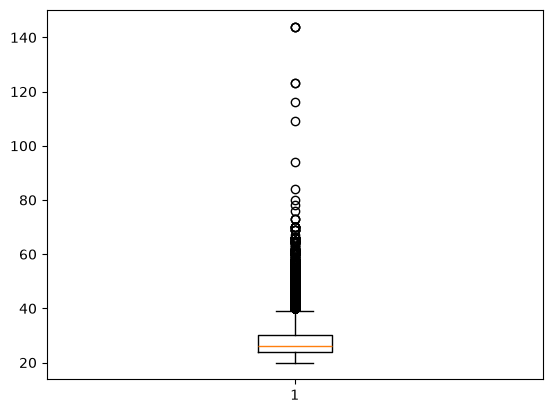

In [8]:
plt.boxplot(df['person_age'])

- high outlier so robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf47de80>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf47e3c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf47dc70>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf47e900>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf47eae0>],
 'means': []}

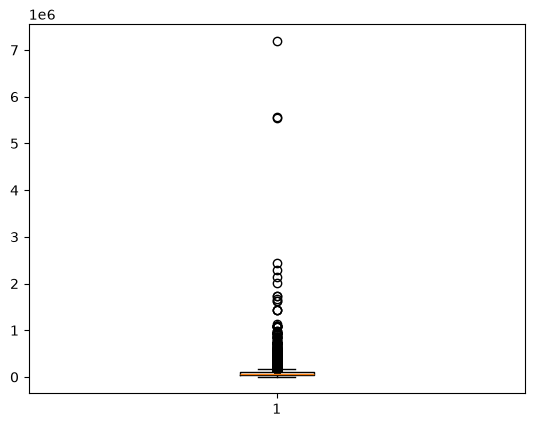

In [9]:
plt.boxplot(df['person_income'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf236a50>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf236f90>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf2367e0>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf2373b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf237650>],
 'means': []}

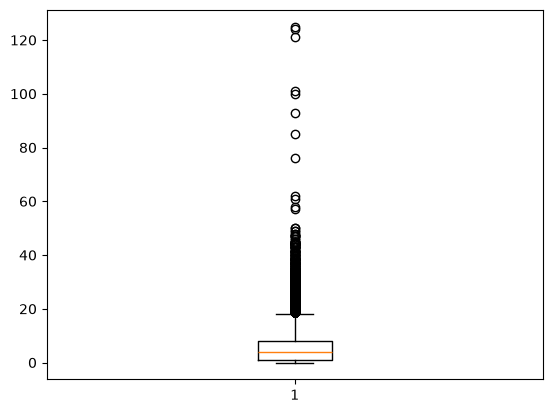

In [10]:
plt.boxplot(df['person_emp_exp'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf29aab0>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf29aff0>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf282b40>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf29b530>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf29b6b0>],
 'means': []}

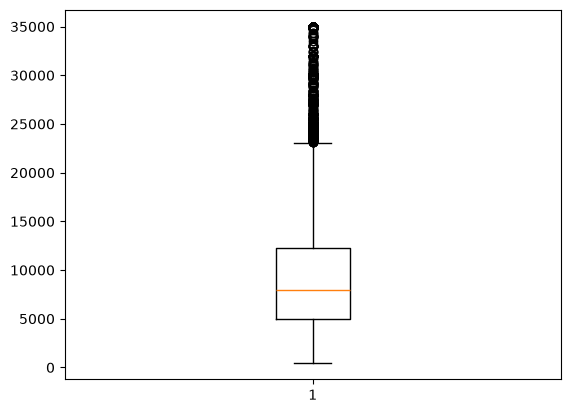

In [11]:
plt.boxplot(df['loan_amnt'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf12c380>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf12c890>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf12c140>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf12cc80>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf12cf20>],
 'means': []}

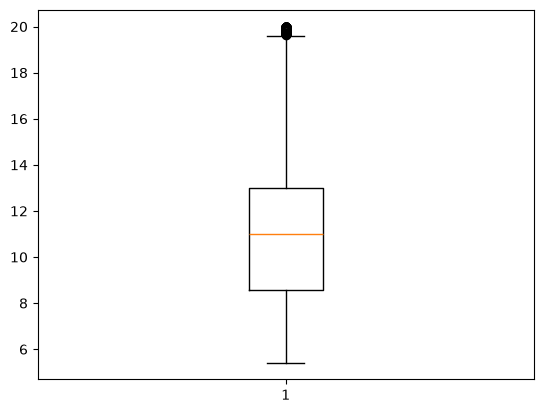

In [12]:
plt.boxplot(df['loan_int_rate'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdf17cf50>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdf17d310>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdf15da60>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdf17d7c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdf17da00>],
 'means': []}

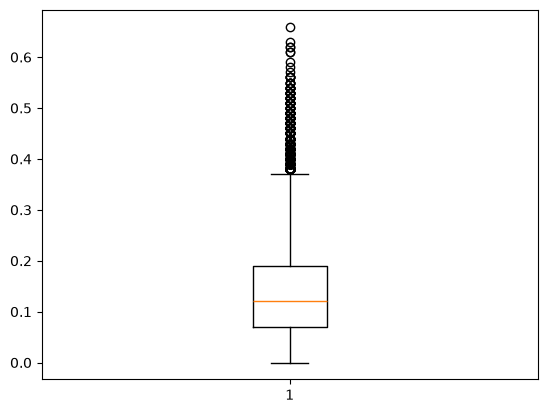

In [13]:
plt.boxplot(df['loan_percent_income'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdcf00f20>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdcf013d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdcf00c80>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdcf017f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdcf01a90>],
 'means': []}

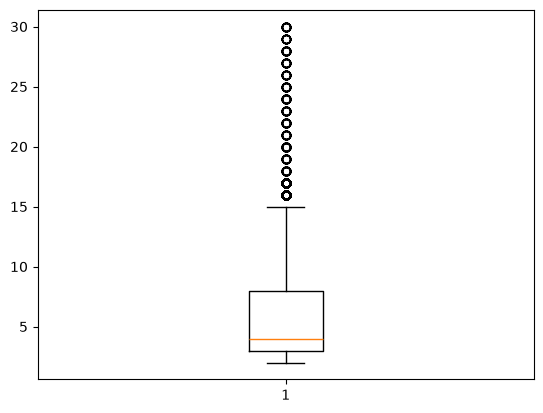

In [14]:
plt.boxplot(df['cb_person_cred_hist_length'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x798bdcf43d10>,
 'caps': [<matplotlib.lines.Line2D at 0x798bdcf64290>,
 'boxes': [<matplotlib.lines.Line2D at 0x798bdcf43aa0>],
 'medians': [<matplotlib.lines.Line2D at 0x798bdcf647a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x798bdcf64a40>],
 'means': []}

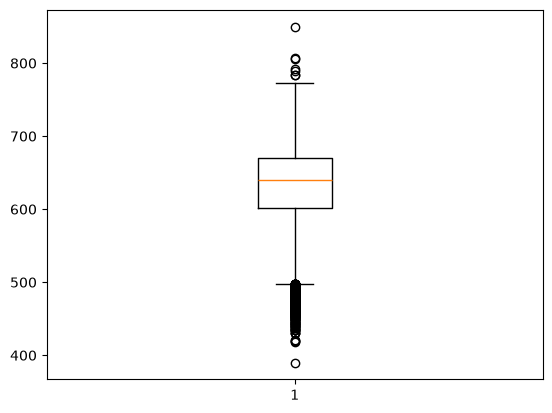

In [15]:
plt.boxplot(df['credit_score'])

- High outliers so Robust scaler

In [16]:
numerical_cols_robust_scaling = ['person_age','person_income','person_emp_exp','loan_amnt','loan_percent_income','credit_score']

numerical_cols_standard_scaling = ['loan_int_rate','cb_person_cred_hist_length']

In [17]:
standard_scalar = StandardScaler()
robust_scalar = RobustScaler()

In [18]:
x_train[numerical_cols_standard_scaling] = standard_scalar.fit_transform(x_train[numerical_cols_standard_scaling])
x_train[numerical_cols_robust_scaling] = robust_scalar.fit_transform(x_train[numerical_cols_robust_scaling])
x_train.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file
25180,1.333333,female,Bachelor,0.621771,1.000000,MORTGAGE,0.965517,PERSONAL,0.577910,0.250000,0.816732,-0.132353,No
12555,-0.166667,male,High School,0.120777,-0.142857,RENT,0.551724,VENTURE,0.286925,0.333333,-0.478914,0.279412,Yes
29153,2.500000,female,Master,5.265159,2.000000,MORTGAGE,2.206897,PERSONAL,-0.211430,-0.416667,1.334990,0.632353,Yes
23838,0.166667,male,Associate,0.559271,0.000000,RENT,0.220690,EDUCATION,2.052907,-0.166667,0.298474,0.014706,No
35686,0.166667,male,Master,0.366411,0.428571,RENT,-0.129793,HOMEIMPROVEMENT,0.658182,-0.333333,-0.738043,0.970588,Yes


In [19]:
x_test[numerical_cols_standard_scaling] = standard_scalar.transform(x_test[numerical_cols_standard_scaling])
x_test[numerical_cols_robust_scaling] = robust_scalar.transform(x_test[numerical_cols_robust_scaling])
x_test.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file
37979,1.000000,male,Associate,0.613528,0.857143,MORTGAGE,-0.068966,EDUCATION,-1.659669,-0.333333,1.075861,-0.573529,No
9911,-0.333333,male,Associate,-0.211303,0.285714,RENT,0.137931,EDUCATION,0.163172,0.333333,-0.478914,0.102941,Yes
43386,-0.666667,female,Master,-0.613961,-0.571429,RENT,-0.413793,MEDICAL,1.297013,0.083333,-0.478914,1.044118,No
13822,-0.500000,female,Bachelor,-0.559435,-0.428571,OWN,-0.413793,VENTURE,0.999338,0.083333,-0.738043,-0.632353,Yes
44810,2.666667,male,High School,0.018175,2.285714,MORTGAGE,0.275862,HOMEIMPROVEMENT,1.474280,0.250000,1.334990,-0.794118,No


## Encoding

In [20]:
# To get the categorical values from the dataset. 
# specifically from the the input feature columns 
categorical_cols = x.select_dtypes(include = 'object').columns


print(categorical_cols)

Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='str')


/tmp/ipykernel_6153/1054614932.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x.select_dtypes(include = 'object').columns


In [21]:
for i in categorical_cols:
    print(df[i].unique())

<StringArray>
['female', 'male']
Length: 2, dtype: str
<StringArray>
['Master', 'High School', 'Bachelor', 'Associate', 'Doctorate']
Length: 5, dtype: str
<StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
<StringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [22]:
categorical_cols_one_hot_encoding = ['person_gender','previous_loan_defaults_on_file','person_home_ownership','loan_intent']

categorical_cols_ordinal_encoding = ['person_education']

# categorical_cols_target_encoding = ['person_home_ownership','loan_intent']

## One Hot Encoding

In [23]:
onehot_encoder = OneHotEncoder(
    sparse_output= False,    # True or False
    handle_unknown='ignore' # 'ignore' or 'error'
)

encoded_values = onehot_encoder.fit_transform(x_train[categorical_cols_one_hot_encoding])

In [24]:
encoded_cols = onehot_encoder.get_feature_names_out()
encoded_cols

# it gives us all the column names of the newly generated columns afte rthe OneHotEncoding
# It follows the pattern of ColumnName_UniqueValueName

array(['person_gender_female', 'person_gender_male',
       'previous_loan_defaults_on_file_No',
       'previous_loan_defaults_on_file_Yes',
       'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION',
       'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL',
       'loan_intent_PERSONAL', 'loan_intent_VENTURE'], dtype=object)

In [25]:
x_train[encoded_cols] = encoded_values

x_train = x_train.drop(columns = categorical_cols_one_hot_encoding)

x_train.head()


,person_age,person_education,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_female,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
25180,1.333333,Bachelor,0.621771,1.000000,0.965517,0.577910,0.250000,0.816732,-0.132353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12555,-0.166667,High School,0.120777,-0.142857,0.551724,0.286925,0.333333,-0.478914,0.279412,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
29153,2.500000,Master,5.265159,2.000000,2.206897,-0.211430,-0.416667,1.334990,0.632353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
23838,0.166667,Associate,0.559271,0.000000,0.220690,2.052907,-0.166667,0.298474,0.014706,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
35686,0.166667,Master,0.366411,0.428571,-0.129793,0.658182,-0.333333,-0.738043,0.970588,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [26]:
x_test[encoded_cols] = onehot_encoder.transform(x_test[categorical_cols_one_hot_encoding])

x_test = x_test.drop(columns = categorical_cols_one_hot_encoding)

x_test.head()

,person_age,person_education,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_female,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
37979,1.000000,Associate,0.613528,0.857143,-0.068966,-1.659669,-0.333333,1.075861,-0.573529,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9911,-0.333333,Associate,-0.211303,0.285714,0.137931,0.163172,0.333333,-0.478914,0.102941,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
43386,-0.666667,Master,-0.613961,-0.571429,-0.413793,1.297013,0.083333,-0.478914,1.044118,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
13822,-0.500000,Bachelor,-0.559435,-0.428571,-0.413793,0.999338,0.083333,-0.738043,-0.632353,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
44810,2.666667,High School,0.018175,2.285714,0.275862,1.474280,0.250000,1.334990,-0.794118,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Ordinal Encoder

In [27]:
ord_encoder = OrdinalEncoder(
    categories= [['High School', 'Bachelor','Master', 'Associate', 'Doctorate']],
    handle_unknown= 'error',     # 'error' or 'use_encoded_value'

)

ord_encoded_value = ord_encoder.fit_transform(x_train[categorical_cols_ordinal_encoding])
ord_encoded_value

array([[1.],
       [0.],
       [2.],
       ...,
       [3.],
       [2.],
       [0.]], shape=(36000, 1))

In [28]:
x_train['person_education'] = ord_encoded_value

x_train.head()

,person_age,person_education,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_female,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
25180,1.333333,1.0,0.621771,1.000000,0.965517,0.577910,0.250000,0.816732,-0.132353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12555,-0.166667,0.0,0.120777,-0.142857,0.551724,0.286925,0.333333,-0.478914,0.279412,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
29153,2.500000,2.0,5.265159,2.000000,2.206897,-0.211430,-0.416667,1.334990,0.632353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
23838,0.166667,3.0,0.559271,0.000000,0.220690,2.052907,-0.166667,0.298474,0.014706,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
35686,0.166667,2.0,0.366411,0.428571,-0.129793,0.658182,-0.333333,-0.738043,0.970588,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [29]:
x_test["person_education"] = ord_encoder.transform(x_test[['person_education']])

x_test["person_education"]

37979    3.0
9911     3.0
43386    2.0
13822    1.0
44810    0.0
        ... 
14572    1.0
30384    0.0
36665    2.0
30569    3.0
5321     0.0
Name: person_education, Length: 9000, dtype: float64

### AFTER PREPROCESSING

In [30]:
x_train.head(10)

,person_age,person_education,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_female,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
25180,1.333333,1.0,0.621771,1.000000,0.965517,0.577910,0.250000,0.816732,-0.132353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12555,-0.166667,0.0,0.120777,-0.142857,0.551724,0.286925,0.333333,-0.478914,0.279412,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
29153,2.500000,2.0,5.265159,2.000000,2.206897,-0.211430,-0.416667,1.334990,0.632353,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
23838,0.166667,3.0,0.559271,0.000000,0.220690,2.052907,-0.166667,0.298474,0.014706,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
35686,0.166667,2.0,0.366411,0.428571,-0.129793,0.658182,-0.333333,-0.738043,0.970588,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
34245,0.500000,0.0,-0.000556,0.428571,-0.551724,-0.004061,-0.500000,0.039344,-0.794118,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
31360,3.166667,3.0,0.860275,2.571429,-0.758621,0.330405,-0.833333,1.853248,1.411765,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
31474,2.166667,0.0,1.064427,2.000000,0.000000,0.832105,-0.416667,2.630635,-0.470588,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
15004,-0.166667,1.0,1.606965,-0.285714,2.344828,0.909032,0.416667,-0.738043,-1.441176,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
13082,-0.666667,2.0,0.815723,-0.571429,1.103448,0.236755,0.250000,-0.738043,0.485294,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [31]:
x_test.head(10)

,person_age,person_education,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_female,...,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
37979,1.000000,3.0,0.613528,0.857143,-0.068966,-1.659669,-0.333333,1.075861,-0.573529,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9911,-0.333333,3.0,-0.211303,0.285714,0.137931,0.163172,0.333333,-0.478914,0.102941,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
43386,-0.666667,2.0,-0.613961,-0.571429,-0.413793,1.297013,0.083333,-0.478914,1.044118,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
13822,-0.500000,1.0,-0.559435,-0.428571,-0.413793,0.999338,0.083333,-0.738043,-0.632353,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
44810,2.666667,0.0,0.018175,2.285714,0.275862,1.474280,0.250000,1.334990,-0.794118,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
18495,0.833333,1.0,-0.789800,0.428571,-0.482759,-1.743285,0.333333,0.816732,0.426471,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
25555,0.833333,1.0,0.694823,0.428571,0.551724,0.474226,0.000000,0.298474,0.441176,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
13316,-0.166667,1.0,-0.442718,-0.142857,-0.717241,1.768610,-0.500000,-0.738043,-0.176471,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
12929,-0.166667,0.0,0.446881,-0.571429,0.551724,0.036075,0.166667,-0.478914,-0.735294,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
28374,0.500000,3.0,-0.250744,0.571429,0.551724,0.664872,0.833333,0.557603,0.470588,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [32]:
x_train.columns

Index(['person_age', 'person_education', 'person_income', 'person_emp_exp',
       'loan_amnt', 'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length', 'credit_score', 'person_gender_female',
       'person_gender_male', 'previous_loan_defaults_on_file_No',
       'previous_loan_defaults_on_file_Yes', 'person_home_ownership_MORTGAGE',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION',
       'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT',
       'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE'],
      dtype='str')

### Modelling

In [33]:
model = LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [34]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

### Model Performance evaluation by the classification metrics

In [ ]:
y.value_counts()

loan_status
0    35000
1    10000
Name: count, dtype: int64

- dataset is imbalenced
- so we cant use the accuracy score here

In [50]:
y_train.value_counts()

loan_status
0    28010
1     7990
Name: count, dtype: int64

In [49]:
# 1. confusion matrix:
# on train data

cf_train = confusion_matrix(y_train,y_train_pred)

cf_train

array([[26315,  1695],
       [ 2004,  5986]])

Note:
- here first row (and column) represents the 0 ('not approved')
- here second row (and column) represents the 1 ('approved')

In [51]:
# 2. recall score (i.e row-wise)

# for label =0 i.e 'not approved'


recall_score_for_not_approved = cf_train[0,0] / (cf_train[0,0] + cf_train[0,1])

recall_score_for_not_approved

np.float64(0.9394858978936095)

conclusion:
- out of 28010 'not approved' samples, 
- 93.9% samples are correctly predicted as 'not approved'
- and remaining 6.1% samples are wrongly predicted as 'approved'

In [52]:
# recall score for label =1 i.e 'approved'
# i.e row-wise

recall_score_for_approved = cf_train[1,1] / (cf_train[1,1] + cf_train[1,0])

recall_score_for_approved

np.float64(0.7491864831038798)

conclusion:
- out of 7990 actually 'approved' samples, 
- 74.9% samples are correctly predicted as 'approved'
- and remaining 25.1% samples are wrongly predicted as 'not approved'

In [53]:
# 3. precision score (i.e column-wise)

# for label =0 i.e 'not approved'


precision_score_for_not_approved = cf_train[0,0] / (cf_train[0,0] + cf_train[1,0])

precision_score_for_not_approved

np.float64(0.9292347893640313)

conclusion:
- out of 28319 samples predicted as 'not approved', 
- 92.9% samples are actually 'not approved' samples
- and remaining 7.1% samples are wrongly predicted as 'not approved'

In [54]:
# precision score for label =1 i.e 'approved'
# i.e column-wise

precision_score_for_approved = cf_train[1,1] / (cf_train[1,1] + cf_train[0,1])

precision_score_for_approved

np.float64(0.7793256086447077)

conclusion:
- out of 7681 samples predicted as 'approved', 
- 77.9% samples are actually 'approved' samples
- and remaining 22.1% samples are wrongly predicted as 'approved'

In [55]:
cf_test = confusion_matrix(y_test,y_test_pred)

cf_test

array([[6552,  438],
       [ 519, 1491]])

### Directly calling recall and precision values 
- i.e without manual calculation
- we can also specify if we want a recall/precision value of a specific label via 'pos_label' argument (i.e position_label)

In [59]:

'''
pos_label is used for mentioning which target value we are finding the recall for 

default is 1

we can change it to get recall score for any of the labels we need like 0,1,...

the target column should be numerical

i.e we should label encoder to convert target column into numerical values if it is not numerical

but for logistic regression , this convertion will happen automatically. so no need to mention explicitly.
'''

recall_score(y_train,y_train_pred,pos_label = 1)


0.7491864831038798

In [61]:
precision_score(y_train,y_train_pred,pos_label = 1)

0.7793256086447077

# Note:
- Check the values of the recall and precision and recall values we calculated aboue with the aboue direct codes, by changing the values of pos_label 